# TP 2 HOMEWORK BUILD ID3 DECISION TREE MODEL FROM SCRATCH
this homework isnt going to be implementation of sci-kit learn because sci-kit learn use CART model in the decision trees models

## IMPORT LIBRARIES

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import math


## FETCH DATA 

In [2]:
data = pd.read_csv('Titanic.csv')
display(data.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Have a look on data

In [3]:
print(f'data shape :\t{data.shape}')
print(f'data description :\t{data.describe()}')
print(f'missed values or null :\t{data.isna().sum()}')
for collumn , series in data.items():
    print(f'Unique values and there count of {collumn} is : \t{series.value_counts()}')


data shape :	(891, 12)
data description :	       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  
missed values or null :	PassengerId    

# DATA MANIPULATION 

*doing map and cut them to categories to make classification easier and predect who survived and who not*

In [4]:
dataset = data.copy()

dataset = dataset.drop(columns=['Cabin', 'Name', 'PassengerId'])
dataset = dataset.dropna(subset=['Embarked'])

meanAge = dataset['Age'].median()
dataset['Age'] = dataset['Age'].fillna(meanAge)
dataset['Sex'] = dataset['Sex'].map({'male': 1, 'female': 0})

display(dataset.head())


,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,0,3,1,22.0,1,0,A/5 21171,7.2500,S
1,1,1,0,38.0,1,0,PC 17599,71.2833,C
2,1,3,0,26.0,0,0,STON/O2. 3101282,7.9250,S
3,1,1,0,35.0,1,0,113803,53.1000,S
4,0,3,1,35.0,0,0,373450,8.0500,S


# Notes
- Survived : binary
- Pclass: categorial
- Sex: binary
- age: contineous
- ticket: string (mostly it will be droped)
- fare : countineous
- embarked : can be categorial ( 0 1 2)

In [5]:
print(f'{'='*50}\tAFTER FIRST ClEANING\t{'='*50}')
print(f'Cleaned Data Shape :\t{dataset.shape}')
print(f'After first cleaning phase is {dataset.isna().sum()}')
print(f'The unique values of Embarked Collumn is :\t{dataset['Embarked'].unique()}')
print(f'Ticket value counts is :\t{dataset['Ticket'].value_counts()}')


==================================================	AFTER FIRST ClEANING	==================================================
Cleaned Data Shape :	(889, 9)
After first cleaning phase is Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Embarked    0
dtype: int64
The unique values of Embarked Collumn is :	<StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str
Ticket value counts is :	Ticket
347082             7
1601               7
CA. 2343           7
3101295            6
CA 2144            6
                  ..
SOTON/OQ 392076    1
211536             1
112053             1
111369             1
370376             1
Name: count, Length: 680, dtype: int64


In [6]:
dataset = dataset.drop(columns=['Ticket'])
dataset['Embarked'] = dataset['Embarked'].map({'C': 0, 'Q': 1, 'S': 2})
dataset['Age']= pd.cut(dataset['Age'],
                       bins= [0, 12, 18, 50, 100],
                       labels=[0, 1, 2, 3])

dataset['Fare']=pd.qcut(dataset['Fare'],
                        q= 3, labels=[0, 1, 2])

display(dataset.head())

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,2,1,0,0,2
1,1,1,0,2,1,0,2,0
2,1,3,0,2,0,0,0,2
3,1,1,0,2,1,0,2,2
4,0,3,1,2,0,0,0,2


# Numerical EMBARKED
C = 0 , Q = 1, S = 2

# DATA ANALYSING

==================================================	AFTER ClEANING	==================================================
data shape :	(889, 8)
data description :	         Survived      Pclass         Sex       SibSp       Parch    Embarked
count  889.000000  889.000000  889.000000  889.000000  889.000000  889.000000
mean     0.382452    2.311586    0.649044    0.524184    0.382452    1.535433
std      0.486260    0.834700    0.477538    1.103705    0.806761    0.792088
min      0.000000    1.000000    0.000000    0.000000    0.000000    0.000000
25%      0.000000    2.000000    0.000000    0.000000    0.000000    1.000000
50%      0.000000    3.000000    1.000000    0.000000    0.000000    2.000000
75%      1.000000    3.000000    1.000000    1.000000    0.000000    2.000000
max      1.000000    3.000000    1.000000    8.000000    6.000000    2.000000
missed values or null :	Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtyp

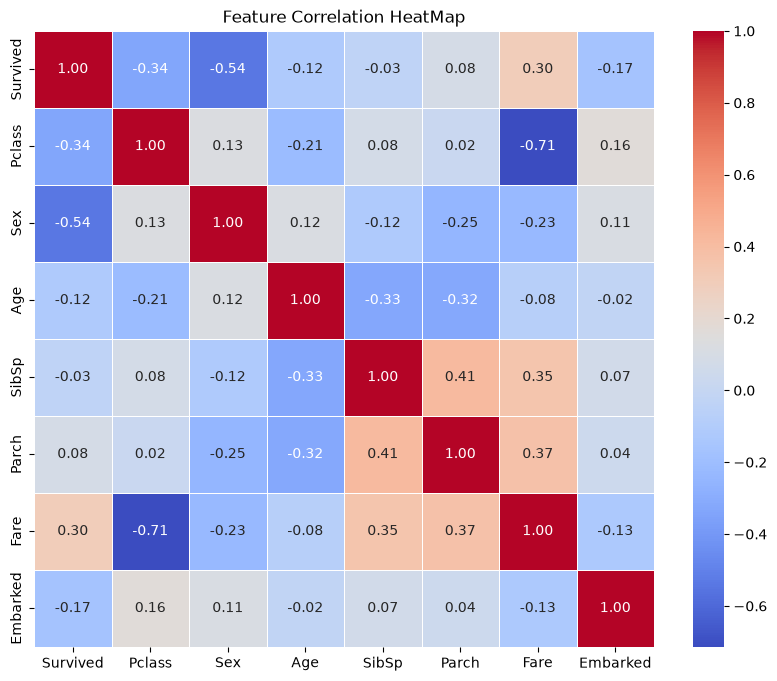

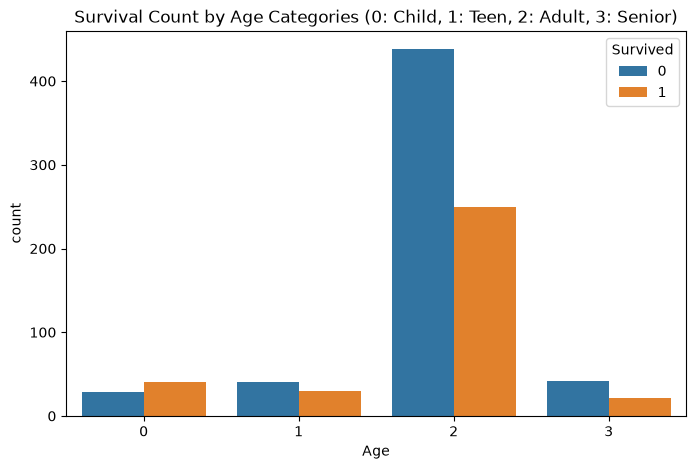

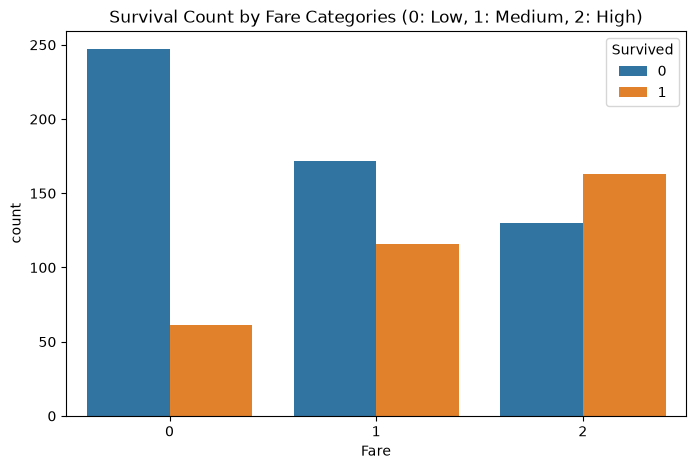

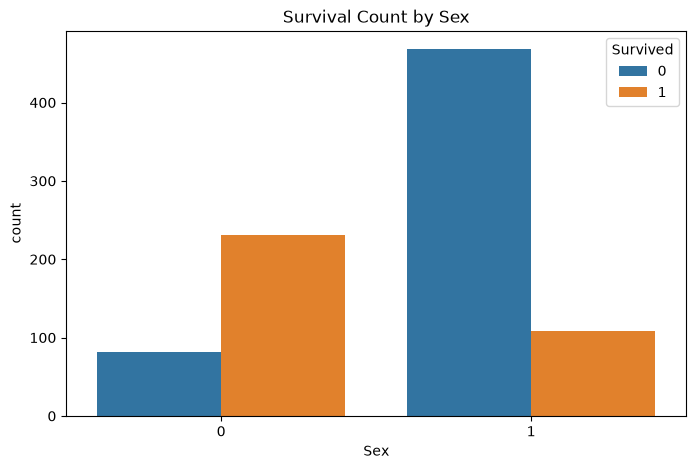

In [7]:
print(f'{'='*50}\tAFTER ClEANING\t{'='*50}')
print(f'data shape :\t{dataset.shape}')
print(f'data description :\t{dataset.describe()}')
print(f'missed values or null :\t{dataset.isna().sum()}')

corrMatrix = dataset.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corrMatrix,
    annot= True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
)
plt.title('Feature Correlation HeatMap')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x='Age', hue='Survived', data=dataset)
plt.title('Survival Count by Age Categories (0: Child, 1: Teen, 2: Adult, 3: Senior)')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x='Fare', hue='Survived', data=dataset)
plt.title('Survival Count by Fare Categories (0: Low, 1: Medium, 2: High)')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x='Sex', hue='Survived', data=dataset)
plt.title('Survival Count by Sex')
plt.show()


# ENTHROPY FUNCTION

In [8]:
def enthropy(one, target):

    enthropies = []
    for col_name, series in one.items():
        val = []
        for v in series.unique():
            mask = (series == v)
            check = target[mask]
            positive = (check == 1).sum()
            negative = (check == 0).sum()
            val.append((positive, negative, len(check)))

        enthro = 0
        for pos, neg, total in val:
            if pos == 0 or neg == 0:
                continue
            else:
                enthro += (-(pos / total) * math.log((pos / total), 2) - (neg / total) * math.log((neg / total), 2)) * (total / len(target))

        enthropies.append(enthro)
    return enthropies



def parentEnthropy(target):
    pos = (target == 1).sum()
    neg = (target == 0).sum()
    total = len(target)

    if pos == 0 or neg == 0:
        return 0.0

    return -(pos / total) * math.log((pos / total), 2) - (neg / total) * math.log((neg / total), 2)

# GAIN FUNCTION

In [9]:
def gain(data , target):
    gainz = []
    parentEnth = parentEnthropy(target)
    enthros = enthropy(data, target)

    for i ,(coll, series) in enumerate(data.items()):
        gainz.append({
            'column': coll,
            'gain': parentEnth - enthros[i],
            'enthropy': enthros[i],
        })

    return gainz



# VOTE FUNCTION

In [10]:
def vote (gainz):
    best = -1
    column = None

    for item in gainz:

        if item['gain']> best:
            best = item['gain']
            column = item['column']

    return column


# TREE ARCHITECTURE ( FLATTENED ARRAY )

In [11]:
class TreeNode:
    def __init__(self, value: object | None, feature: str | None,splitFeature = None,leafValue = None, firstChild: int = -1, nextSubnit: int = -1, parent: int = 0 ):
        self.feature = feature
        self.splitFeature = splitFeature
        self.leafValue = leafValue
        self.value = value
        self.firstChild = firstChild
        self.nextSubnit = nextSubnit
        self.parent = parent


class FlattenedArray:
    def __init__(self, root: TreeNode | None = None):
        if root is None:
            root = TreeNode(None, None)
        self.root = root
        self.data = [(self.root.value, self.root.feature, self.root.splitFeature, self.root.leafValue)]
        self.firstChilds = [-1]
        self.nextSubnit = [-1]
        self.size = 1

    def add(self, node: TreeNode):
        self.data.append((node.value, node.feature, node.splitFeature, node.leafValue ))
        self.firstChilds.append(node.firstChild)
        self.nextSubnit.append(node.nextSubnit)
        index = self.size
        self.size += 1
    

        if self.firstChilds[node.parent] == -1:
            self.firstChilds[node.parent] = index
        else:
            current = self.firstChilds[node.parent]
            while  self.nextSubnit[current] != -1 :
                current = self.nextSubnit[current]

            self.nextSubnit[current] = index

    def delete(self, index):
        
        self.data[index] = None





# TREE BUILDER

In [12]:
def subtree(tree: FlattenedArray, data, target, feature, parents, fallback):
    for val in data[feature].unique():
        mask = data[feature] == val
        subData = data.loc[mask].drop(columns=[feature])
        subTarget = target.loc[mask]

        if subTarget.nunique() == 1 or subData.shape[1] == 0:
            leaf = subTarget.mode().iloc[0] if not subTarget.empty else fallback
            tree.add(TreeNode(value=val, feature=None, splitFeature=feature, leafValue=leaf, parent=parents))
            continue

        gainz = gain(subData, subTarget)
        feat = vote(gainz)
        if feat is None:
            leafValue = subTarget.mode().iloc[0]
            tree.add(TreeNode(subTarget.mode().iloc[0], None, parent=parents, leafValue=leafValue))
            continue

        child = TreeNode(val, feature=feat,splitFeature=feature, parent=parents)
        tree.add(child)
        subtree(tree, subData, subTarget, feat, tree.size - 1, subTarget.mode().iloc[0])


def treeBuilder(data, target):
    fallback = target.mode().iloc[0]
    if data.shape[1] == 0:
        tree = FlattenedArray(TreeNode(fallback, None))
        tree.fallback = fallback
        return tree

    feat = vote(gain(data, target))
    if feat is None:
        tree = FlattenedArray(TreeNode(fallback, None))
        tree.fallback = fallback
        return tree

    tree = FlattenedArray(TreeNode(None, feature=feat))
    tree.fallback = fallback
    subtree(tree, data, target, feat, 0, fallback)
    return tree


# PRIDECT FUNCTION

In [13]:
def pridect(inputs, tree: FlattenedArray, start: int = 0, fallback=None):
    if fallback is None:
        fallback = tree.fallback
    if start < 0:
        return fallback

    value, feature, splitFeature, leafValue= tree.data[start]
    if splitFeature is not None and inputs.get(splitFeature) != value:
            return pridect(inputs, tree, tree.nextSubnit[start], fallback)
    
    if feature is None:
        return leafValue if leafValue is not None else fallback

    child = tree.firstChilds[start]
    if child == -1:
        return fallback
    return pridect(inputs, tree, child, fallback)


# TRYING ID3 DECISION TREE

In [14]:
datatrain,datatest, targettrain ,targettest = train_test_split(dataset.drop(columns='Survived'), dataset['Survived'], test_size=0.2, random_state=42)
tree = treeBuilder(datatrain, targettrain)
preductions = []


for i in range(len(datatest)):
    row = datatest.iloc[i].to_dict()
    preductions.append(pridect(row,tree))

if (len(preductions) != len(targettest)):
    print("errors happened")
else:
    targettest = targettest.tolist()
    correct = 0
    for i in range(len(preductions)):
        if (preductions[i] == targettest[i]):
            correct += 1
    
    print(f'preductions list : \t{preductions}')
    print(f'original output list : \t{targettest}')
    print(f'total values : \t{len(targettest)}')
    print(f'correct values : \t{correct}')
    print(f'accurency : \t{correct* 100 / len(preductions):.2f}%')

preductions list : 	[np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.i

# MUSHROOM DATASET

In [15]:
mushroom = pd.read_csv('mushrooms.csv')

display(mushroom)

print(f'data shape :\t{mushroom.shape}')
print(f'NAN VALUES :\t{mushroom.isna().sum()}')
print('Unique values and there counts :')
for column , series in mushroom.items():
    print(series.value_counts())

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


data shape :	(8124, 23)
NAN VALUES :	class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64
Unique values and there counts :
class
e    4208
p    3916
Name: count, dtype: int64
cap-shape
x    3656
f    3152
k     828
b     452
s      32
c       4
Name: count, dtype: int64
cap-surface
y    3244
s    2556
f    2320
g       4
Name: count, dtype: int64
c

Note : data is clean need just to be enumerated soo easier in treatement 

# Make Data Numerical

In [16]:
for column , series in mushroom.items():
    mushroom[column] = series.map({value: index for index, value in enumerate(sorted(series.unique()))})

display(mushroom.head())

for column , series in mushroom.items():
    print(series.value_counts())



,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,7,7,0,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,7,7,0,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,7,7,0,2,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,7,7,0,2,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,7,7,0,2,1,0,3,0,1


class
0    4208
1    3916
Name: count, dtype: int64
cap-shape
5    3656
2    3152
3     828
0     452
4      32
1       4
Name: count, dtype: int64
cap-surface
3    3244
2    2556
0    2320
1       4
Name: count, dtype: int64
cap-color
4    2284
3    1840
2    1500
9    1072
8    1040
0     168
5     144
1      44
7      16
6      16
Name: count, dtype: int64
bruises
0    4748
1    3376
Name: count, dtype: int64
odor
5    3528
2    2160
8     576
7     576
0     400
3     400
6     256
1     192
4      36
Name: count, dtype: int64
gill-attachment
1    7914
0     210
Name: count, dtype: int64
gill-spacing
0    6812
1    1312
Name: count, dtype: int64
gill-size
0    5612
1    2512
Name: count, dtype: int64
gill-color
0     1728
7     1492
10    1202
5     1048
2      752
3      732
9      492
4      408
1       96
11      86
6       64
8       24
Name: count, dtype: int64
stalk-shape
1    4608
0    3516
Name: count, dtype: int64
stalk-root
1    3776
0    2480
3    1120
2     556
4     19

# TRY THE MODEL AGAIN 

In [17]:
datatrain, datatest, targettrain, targettest = train_test_split(mushroom.drop(columns='class'), mushroom['class'], test_size=0.2, random_state=42, stratify=mushroom['class'])

tree = treeBuilder(datatrain, targettrain)

predictions = []

for i in range(len(datatest)):
    row = datatest.iloc[i].to_dict()
    predictions.append(pridect(row, tree))

targettest = targettest.tolist()

correct = 0
for i in range(len(predictions)):
    if predictions[i] == targettest[i]:
        correct += 1

print(f'total values :\t{len(targettest)}')
print(f'correct values :\t{correct}')
print(f'accuracy :\t{correct * 100 / len(predictions):.2f}%')

total values :	1625
correct values :	1625
accuracy :	100.00%
